# 09.1 · Text to numbers: cleaning, tokens, bag-of-words, TF-IDF by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/01-text-to-numbers/lesson.ipynb)

Read the [README](README.md) first and do the by-hand tables on paper. This notebook reproduces them exactly, then turns 10,000 real reviews into numbers.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

## 1. Four tiny reviews as a bag of words

In [2]:
docs = ["great mug great price",
        "mug arrived broken",
        "great lights",
        "lights arrived late"]

from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
counts = cv.fit_transform(docs)
pd.DataFrame(counts.toarray(), columns=cv.get_feature_names_out(), index=["R1", "R2", "R3", "R4"])

,arrived,broken,great,late,lights,mug,price
R1,0,0,2,0,0,1,1
R2,1,1,0,0,0,1,0
R3,0,0,1,0,1,0,0
R4,1,0,0,1,1,0,0


Same table as the README. The vocabulary is sorted alphabetically, and *great* gets a 2 in R1.

## 2. IDF by hand, then by scikit-learn

$\text{idf}(t) = \ln\big((1+N)/(1+\text{df}(t))\big) + 1$, with $N = 4$.

In [3]:
N = len(docs)
df_t = (counts.toarray() > 0).sum(axis=0)            # documents containing each word
idf_by_hand = np.log((1 + N) / (1 + df_t)) + 1
pd.DataFrame({"documents containing": df_t, "idf": idf_by_hand.round(4)},
             index=cv.get_feature_names_out())

,documents containing,idf
arrived,2,1.5108
broken,1,1.9163
great,2,1.5108
late,1,1.9163
lights,2,1.5108
mug,2,1.5108
price,1,1.9163


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(docs)
print("scikit-learn idf:", dict(zip(tfidf.get_feature_names_out(), tfidf.idf_.round(4))))
pd.DataFrame(X.toarray().round(3), columns=tfidf.get_feature_names_out(), index=["R1", "R2", "R3", "R4"])

scikit-learn idf: {'arrived': np.float64(1.5108), 'broken': np.float64(1.9163), 'great': np.float64(1.5108), 'late': np.float64(1.9163), 'lights': np.float64(1.5108), 'mug': np.float64(1.5108), 'price': np.float64(1.9163)}


,arrived,broken,great,late,lights,mug,price
R1,0.000,0.000,0.778,0.000,0.000,0.389,0.493
R2,0.526,0.668,0.000,0.000,0.000,0.526,0.000
R3,0.000,0.000,0.707,0.000,0.707,0.000,0.000
R4,0.526,0.000,0.000,0.668,0.526,0.000,0.000


### R1 step by step: tf × idf, then divide by the length

In [5]:
idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))
raw = np.array([2 * idf["great"], 1 * idf["mug"], 1 * idf["price"]])
length = np.sqrt((raw ** 2).sum())
print("raw    :", raw.round(4))
print("length :", length.round(3))
print("scaled :", (raw / length).round(3), "  (great, mug, price)")

raw    : [3.0217 1.5108 1.9163]
length : 3.884
scaled : [0.778 0.389 0.493]   (great, mug, price)


## 3. Cleaning and tokenising

The default tokeniser lower-cases, then keeps runs of **two or more** letters or digits. Watch what happens to *I*, *a* and *don't*.

In [6]:
sentence = "I don't think a 2nd mug was EVER this good!!"
print(CountVectorizer().build_tokenizer()(sentence.lower()))

['don', 'think', '2nd', 'mug', 'was', 'ever', 'this', 'good']


**Stemming** chops endings by rule. A toy stemmer is three lines, and it shows both the idea and the problem:

In [7]:
def toy_stem(word):
    for ending in ["ing", "ed", "s"]:
        if word.endswith(ending) and len(word) > len(ending) + 2:
            return word[: -len(ending)]
    return word

words = ["arrived", "arriving", "arrives", "mugs", "broken", "breaks", "lights", "was"]
pd.DataFrame({"word": words, "toy stem": [toy_stem(w) for w in words]})

,word,toy stem
0,arrived,arriv
1,arriving,arriv
2,arrives,arrive
3,mugs,mug
4,broken,broken
5,breaks,break
6,lights,light
7,was,was


*arrived* and *arriving* both become *arriv*, which is the point. But *arrives* only loses its *s* (→ *arrive*), *broken* and *breaks* end up as different words, and *was* is untouched. Rules are crude. A **lemmatiser** (NLTK, spaCy) uses a dictionary and grammar to map *broken → break*, *was → be*. For sentiment on reviews, neither changes much; modern models (09.4 onwards) skip this step entirely.

## 4. Stop words: careful

In [8]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print(len(ENGLISH_STOP_WORDS), "stop words; contains 'not':", "not" in ENGLISH_STOP_WORDS,
      "| 'no':", "no" in ENGLISH_STOP_WORDS)
for sw in [None, "english"]:
    v = CountVectorizer(stop_words=sw).fit(["this mug is not good"])
    print(f"stop_words={sw!s:8} →", list(v.get_feature_names_out()))

318 stop words; contains 'not': True | 'no': True
stop_words=None     → ['good', 'is', 'mug', 'not', 'this']
stop_words=english  → ['good', 'mug']


With stop words removed, *"this mug is not good"* becomes *mug, good*: the opposite meaning. Keep that in mind for 09.2.

## 5. n-grams: a little word order back

In [9]:
v = CountVectorizer(ngram_range=(1, 2)).fit(["the mug was not good at all"])
print(list(v.get_feature_names_out()))

['all', 'at', 'at all', 'good', 'good at', 'mug', 'mug was', 'not', 'not good', 'the', 'the mug', 'was', 'was not']


The bigram *not good* now exists as its own column. The cost: many more columns.

## 6. Ten thousand real reviews

In [10]:
from download import load_reviews
from sklearn.model_selection import train_test_split

reviews = load_reviews()          # first run downloads one 117 MB file, then cached
train, test = train_test_split(reviews, test_size=0.2, random_state=42, stratify=reviews["label"])
print(f"{len(reviews):,} reviews ({reviews['label'].mean():.0%} positive): "
      f"train {len(train):,} / test {len(test):,}")
reviews[["text", "label"]].head()

10,000 reviews (50% positive): train 8,000 / test 2,000


,text,label
0,"Great Book, Must read! Ramon found the fabulou...",1
1,A leaker! This is the second generation of the...,0
2,Not For the Professional Cook. Henckels are we...,0
3,Arg! I'd like to see Robert Jordan put to the ...,0
4,"If I could give this minus 5 stars, I'd give i...",0


In [11]:
cv_all = CountVectorizer()
C = cv_all.fit_transform(reviews["text"])
totals = np.asarray(C.sum(axis=0)).ravel()
vocab = cv_all.get_feature_names_out()
order = totals.argsort()[::-1]
print(f"{totals.sum():,} tokens, {len(vocab):,} different words")
print(f"words used exactly once: {(totals == 1).sum():,} ({(totals == 1).mean():.0%})")
print(f"top 15 words are {totals[order[:15]].sum() / totals.sum():.1%} of all tokens:")
print(list(vocab[order[:15]]))

746,200 tokens, 34,590 different words
words used exactly once: 16,853 (49%)
top 15 words are 26.9% of all tokens:
['the', 'and', 'to', 'it', 'of', 'this', 'is', 'in', 'for', 'that', 'you', 'not', 'was', 'but', 'with']


In [12]:
cv_stop = CountVectorizer(stop_words="english")
C2 = cv_stop.fit_transform(reviews["text"])
totals2 = np.asarray(C2.sum(axis=0)).ravel()
print("top words without stop words:")
print(list(cv_stop.get_feature_names_out()[totals2.argsort()[::-1][:15]]))

top words without stop words:


['book', 'great', 'good', 'like', 'just', 'read', 'time', 'movie', 'don', 'really', 'love', 'buy', 'cd', 'product', 'best']


A log-log plot of word frequency against rank is almost a straight line. This pattern (Zipf's law) holds for nearly every language and text collection.

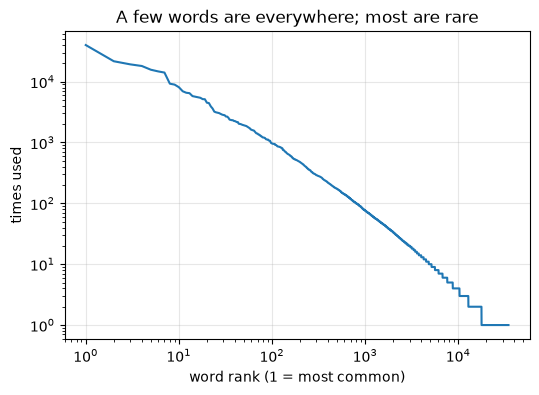

In [13]:
plt.figure(figsize=(6, 4))
plt.loglog(np.arange(1, len(totals) + 1), np.sort(totals)[::-1])
plt.xlabel("word rank (1 = most common)"); plt.ylabel("times used")
plt.title("A few words are everywhere; most are rare"); plt.grid(alpha=.3)
plt.show()

### The feature matrix 09.2 will use (fitted on the training reviews only)

In [14]:
for ngrams, min_df in [((1, 1), 1), ((1, 1), 2), ((1, 2), 2)]:
    vec = TfidfVectorizer(ngram_range=ngrams, min_df=min_df)
    Xtr = vec.fit_transform(train["text"])
    print(f"ngram_range={ngrams}, min_df={min_df}: {len(vec.vocabulary_):>6,} columns, "
          f"{Xtr.nnz / Xtr.shape[0]:.1f} non-zero per review, "
          f"{100 * Xtr.nnz / np.prod(Xtr.shape):.2f}% of cells filled")

ngram_range=(1, 1), min_df=1: 30,631 columns, 54.8 non-zero per review, 0.18% of cells filled
ngram_range=(1, 1), min_df=2: 14,060 columns, 52.8 non-zero per review, 0.38% of cells filled


ngram_range=(1, 2), min_df=2: 66,583 columns, 98.6 non-zero per review, 0.15% of cells filled


Fewer than 1 cell in 500 is non-zero. A dense table of 8,000 × 66,583 floats would need about 4 GB; the sparse matrix needs a few megabytes.

## Quiz answers

1. **Word order** (and grammar). Only the counts survive.
2. It appears in almost every document, so $\text{df}$ is close to $N$ and $\ln\frac{1+N}{1+\text{df}}$ is close to 0.
3. So that long and short reviews with the same mix of words get comparable scores; otherwise length would dominate.
4. Stop-word lists include negations such as *not* and *no*, so *"not good"* turns into *"good"*.
5. A **sparse** matrix, which stores only the non-zero cells.

**Next:** [09.2 Sentiment classifier](../02-sentiment-classifier/)